# How much revenue do ASOS stock-outs put at risk, and how sure can we be?

A product page shows which sizes are out of stock. The tempting step is price x missing sizes = lost revenue. A single scrape has no sales, no stock levels and no date, so that sum rests on assumptions. This notebook cleans the data, finds where stock-outs happen, and tests how far the estimate moves when the assumptions change.

The idea of estimating "phantom revenue" comes from [this tutorial by Lore So What](https://www.youtube.com/watch?v=ux9uxKM171E). The cleaning, size analysis and scenarios are my own.

In [1]:
import os, re, warnings
from pathlib import Path

warnings.filterwarnings("ignore", category=UserWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 160, "display.max_columns", 30)

CSV = Path(os.environ.get("ASOS_CSV", "../data/raw/products_asos.csv"))
FIG = Path("../figures")
FIG.mkdir(exist_ok=True)

INK, MUTED, GRID, ACCENT = "#22262b", "#6b7280", "#e5e7eb", "#1f5fae"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 170, "savefig.bbox": "tight",
    "font.size": 10, "text.color": INK, "axes.labelcolor": MUTED,
    "xtick.color": MUTED, "ytick.color": INK, "axes.edgecolor": GRID,
    "axes.spines.top": False, "axes.spines.right": False,
})

raw = pd.read_csv(CSV, low_memory=False)
raw.shape

(30845, 9)

## 1. Cleaning

Things that are wrong or awkward in the raw file:

- Some rows repeat the same product, so `sku` has to be the key.
- For some rows the URL points at a different product from the name. The product code inside `description` always matches `sku`, so the URL is the broken field.
- `price` mixes numbers with text like `Now 14.50` and `From 42.50`.
- Brand and category have no clean column.

In [2]:
def slug(text):
    text = re.sub(r"[^a-z0-9 -]", "", str(text).lower())
    return re.sub(r"-+", "-", text.replace(" ", "-")).strip("-")

df = raw.dropna(subset=["sku", "size", "price", "name"]).copy()
df["name_slug"] = df.name.map(slug)
df["url_slug"] = df.url.str.extract(r"/([a-z0-9-]+)/prd/")[0].fillna("")

def overlap(a, b):
    a, b = set(a.split("-")), set(b.split("-"))
    return len(a & b) / max(1, len(a | b))

df["url_match"] = [overlap(a, b) for a, b in zip(df.name_slug, df.url_slug)]
code_matches = df.description.str.extract(r"Product Code: ?(\d+)")[0].astype(float).eq(df.sku).mean()

report = {
    "rows with data": len(df),
    "unique SKUs": df.sku.nunique(),
    "repeat rows": len(df) - df.sku.nunique(),
    "rows where URL does not match name (word overlap < 0.3)": int(df.url_match.lt(0.3).sum()),
    "share of rows where product code = sku": round(float(code_matches), 4),
}
df = df.sort_values("url_match", ascending=False).drop_duplicates("sku").copy()

df["price_type"] = df.price.astype(str).str.extract(r"^(Now|From)")[0].fillna("Full")
df["price_value"] = pd.to_numeric(df.price.astype(str).str.replace(r"[^0-9.]", "", regex=True))
df["sizes"] = df["size"].map(lambda s: [x.strip() for x in s.split(",") if x.strip()])
df["n_sizes"] = df.sizes.str.len()
df["n_out"] = df.sizes.map(lambda items: sum("Out of stock" in x for x in items))
df = df[df.n_sizes.gt(1)].copy()

report["multi-size SKUs kept"] = len(df)
report["SKUs with every size out of stock"] = int(df.n_sizes.eq(df.n_out).sum())
pd.Series(report).to_frame("value")

,value
rows with data,30827.0
unique SKUs,29971.0
repeat rows,856.0
rows where URL does not match name (word overlap < 0.3),483.0
share of rows where product code = sku,1.0
multi-size SKUs kept,29843.0
SKUs with every size out of stock,0.0


In [3]:
suffix = r"-(curve|tall|petite|plus|maternity)$"
known = {re.sub(suffix, "", u) for u in
         raw.url.dropna().str.extract(r"asos\.com/([a-z0-9-]+)/")[0].dropna().unique()}

def brand_of(name_slug):
    parts = name_slug.split("-")
    for n in range(min(5, len(parts)), 0, -1):
        candidate = "-".join(parts[:n])
        if candidate in known:
            return candidate
    return "unknown"

def pretty(b):
    fixes = {"asos-design": "ASOS DESIGN", "asos-luxe": "ASOS LUXE", "asos-edition": "ASOS EDITION",
             "asos-4505": "ASOS 4505", "other-stories": "& Other Stories",
             "pullbear": "Pull&Bear", "na-kd": "NA-KD", "yas": "Y.A.S", "asyou": "ASYOU",
             "extro-vert": "Extro & Vert", "wednesdays-girl": "Wednesday's Girl",
             "nobodys-child": "Nobody's Child", "adidas": "adidas", "adidas-originals": "adidas Originals"}
    return fixes.get(b, b.replace("-", " ").title())

df["brand"] = df.name_slug.map(brand_of).map(pretty)

GROUPS = [("Lingerie & nightwear", r"bra\b|brief|thong|pyjama|lingerie|nightdress|bodysuit"),
          ("Swimwear", r"bikini|swim"),
          ("Dresses", r"dress"), ("Skirts", r"skirt"), ("Jeans", r"jean"),
          ("Trousers & shorts", r"trouser|legging|jogger|short"),
          ("Coats & jackets", r"coat|jacket|blazer|puffer|parka|gilet"),
          ("Knitwear", r"jumper|cardigan|knit"),
          ("Tops", r"top\b|tee\b|t-shirt|shirt|blouse|vest|cami|sweatshirt|hoodie")]

def group_of(name):
    low = name.lower()
    for label, pattern in GROUPS:
        if re.search(pattern, low):
            return label
    return "Other"

df["group"] = df.name.map(group_of)
print(f"Brand not identified: {df.brand.eq('Unknown').mean():.2%}")
print(f"Group 'Other': {df.group.eq('Other').mean():.2%}")
print(f"Brands found: {df.brand.nunique()}")

Brand not identified: 0.70%
Group 'Other': 4.59%
Brands found: 274


## 2. Where stock-outs happen

Not a single SKU in the file has every size sold out. That is suspicious: either sold-out products disappear from the listing or the scraper skipped them. So the data misses the most severe stock-outs, and every number below is a lower bound on that side.

Size-level stock-out rate: 28.2%
SKUs with at least one missing size: 56.0%


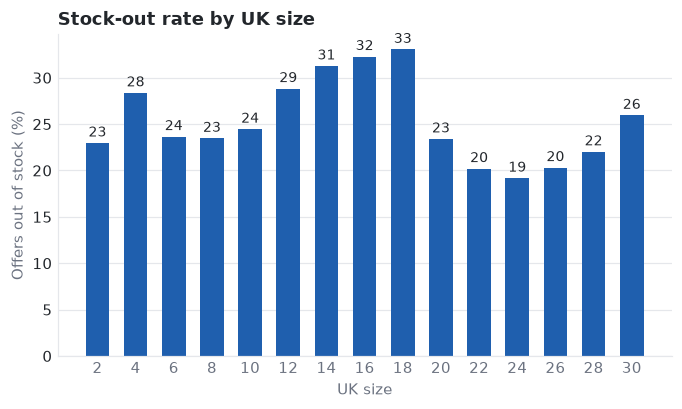

,rate,offers
uk,,
2,23.0%,553
4,28.4%,"9,298"
6,23.7%,"13,198"
8,23.5%,"13,655"
10,24.5%,"13,620"
12,28.8%,"13,669"
14,31.3%,"13,636"
16,32.3%,"14,743"
18,33.0%,"12,164"


In [4]:
rate = df.n_out.sum() / df.n_sizes.sum()
print(f"Size-level stock-out rate: {rate:.1%}")
print(f"SKUs with at least one missing size: {df.n_out.gt(0).mean():.1%}")

pattern = re.compile(r"^UK (\d+)( - Out of stock)?$")
rows = []
for items in df.sizes:
    for item in items:
        m = pattern.match(item)
        if m:
            rows.append((int(m[1]), m[2] is not None))
uk = pd.DataFrame(rows, columns=["uk", "out"])
uk_rate = uk.groupby("uk").out.agg(rate="mean", offers="size")
uk_rate = uk_rate[uk_rate.offers.ge(500)]

fig, ax = plt.subplots(figsize=(7.2, 3.8))
ax.bar(uk_rate.index.astype(str), uk_rate.rate * 100, color=ACCENT, width=0.62)
for i, value in enumerate(uk_rate.rate * 100):
    ax.text(i, value + 0.7, f"{value:.0f}", ha="center", fontsize=9)
ax.set_xlabel("UK size")
ax.set_ylabel("Offers out of stock (%)")
ax.grid(axis="y", color=GRID, lw=0.8); ax.set_axisbelow(True); ax.tick_params(length=0)
ax.set_title("Stock-out rate by UK size", loc="left", fontweight="bold")
fig.savefig(FIG / "stockout_by_uk_size.png")
plt.show()
uk_rate.style.format({"rate": "{:.1%}", "offers": "{:,}"})

In [5]:
def position(items):
    out = []
    n = len(items)
    for i, item in enumerate(items):
        where = "smallest" if i == 0 else "largest" if i == n - 1 else "middle"
        out.append((where, "Out of stock" in item))
    return out

pos = pd.DataFrame([p for items in df.loc[df.n_sizes.ge(4), "sizes"] for p in position(items)],
                   columns=["position", "out"])
print(pos.groupby("position").out.mean().map("{:.1%}".format))

by_type = df.groupby("price_type").apply(lambda g: pd.Series({
    "skus": len(g), "stockout_rate": g.n_out.sum() / g.n_sizes.sum()}), include_groups=False)
by_group = df.groupby("group").apply(lambda g: pd.Series({
    "skus": len(g), "stockout_rate": g.n_out.sum() / g.n_sizes.sum(),
    "median_price": g.price_value.median()}), include_groups=False).sort_values("stockout_rate", ascending=False)
display(by_type.style.format({"stockout_rate": "{:.1%}", "skus": "{:,.0f}"}))
by_group.style.format({"stockout_rate": "{:.1%}", "skus": "{:,.0f}", "median_price": "{:.2f}"})

position
largest     35.7%
middle      27.6%
smallest    24.4%
Name: out, dtype: str


,skus,stockout_rate
price_type,,
From,72,16.8%
Full,"17,784",28.1%
Now,"11,987",28.5%


,skus,stockout_rate,median_price
group,,,
Knitwear,"2,497",42.8%,24.50
Coats & jackets,"3,647",36.5%,50.00
Lingerie & nightwear,"1,680",30.7%,20.00
Trousers & shorts,"2,052",29.8%,32.00
Other,"1,369",28.8%,26.00
Tops,"7,023",27.9%,22.00
Dresses,"10,969",22.5%,41.50
Jeans,273,22.3%,42.00
Skirts,276,21.5%,28.00


## 3. Brands

Only brands with 150 or more SKUs, so one product cannot swing the rate.

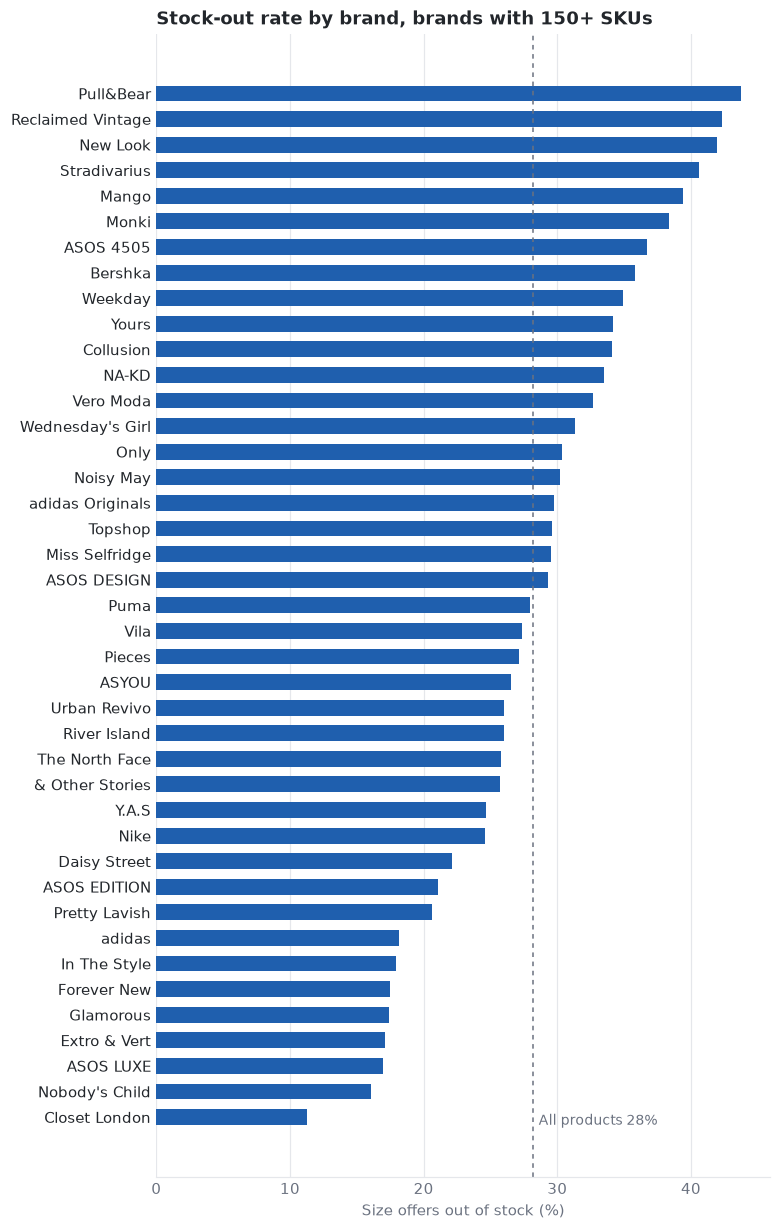

,skus,stockout_rate,exposure
brand,,,
Pull&Bear,286,43.7%,"15,419"
Reclaimed Vintage,253,42.3%,"23,086"
New Look,608,42.0%,"42,343"
Stradivarius,423,40.6%,"22,404"
Mango,232,39.4%,"20,681"
Monki,584,38.3%,"41,675"
ASOS 4505,223,36.7%,"12,520"
Bershka,468,35.8%,"18,126"
Weekday,306,34.9%,"17,146"


In [6]:
brands = df.groupby("brand").apply(lambda g: pd.Series({
    "skus": len(g), "stockout_rate": g.n_out.sum() / g.n_sizes.sum(),
    "exposure": (g.price_value * g.n_out).sum()}), include_groups=False)
big = brands[brands.skus.ge(150) & brands.index.to_series().ne("Unknown")].sort_values("stockout_rate")

fig, ax = plt.subplots(figsize=(7.2, 0.3 * len(big) + 1.2))
ax.barh(big.index, big.stockout_rate * 100, color=ACCENT, height=0.62)
ax.axvline(rate * 100, color=MUTED, lw=1, ls=(0, (3, 3)))
ax.text(rate * 100 + 0.4, -0.15, f"All products {rate * 100:.0f}%", color=MUTED, fontsize=9, va="center")
ax.set_xlabel("Size offers out of stock (%)")
ax.grid(axis="x", color=GRID, lw=0.8); ax.set_axisbelow(True)
ax.tick_params(length=0); ax.spines["left"].set_visible(False)
ax.set_title("Stock-out rate by brand, brands with 150+ SKUs", loc="left", fontweight="bold")
fig.savefig(FIG / "stockout_by_brand.png")
plt.show()
big.sort_values("stockout_rate", ascending=False).style.format({"skus": "{:,.0f}", "stockout_rate": "{:.1%}", "exposure": "{:,.0f}"})

## 4. How far does the estimate move?

Each scenario changes one thing. The multipliers are assumptions, not measurements, and they are there to show sensitivity.

| Scenario | Assumption |
|---|---|
| Baseline | Each missing size loses one sale at the current price |
| Full-price only | Sale stock is excluded, since selling out on sale may be the plan |
| Substitution 50% | Half of those customers buy another size or item anyway |
| Edge sizes half demand | The smallest and largest size in a range count as half a sale |
| Cautious | All three together |

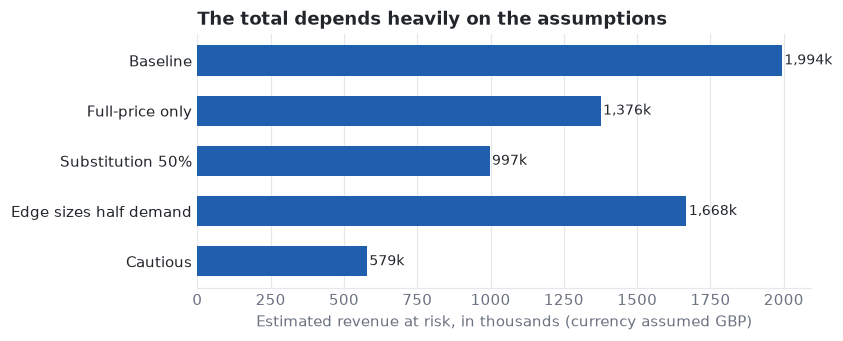

,estimate,vs_baseline
Baseline,"1,993,627",100%
Full-price only,"1,375,506",69%
Substitution 50%,"996,814",50%
Edge sizes half demand,"1,668,126",84%
Cautious,"578,511",29%


Brands compared: 41. Substitution 50% is a flat multiplier, so its ranking matches the baseline by construction.


,spearman_vs_baseline,top10_shared_with_baseline
Baseline,1.000,10
Full-price only,0.975,9
Substitution 50%,1.000,10
Edge sizes half demand,0.997,10
Cautious,0.980,9


In [7]:
def weighted_out(items):
    n = len(items)
    return sum(0.5 if i in (0, n - 1) and n >= 4 else 1.0
               for i, item in enumerate(items) if "Out of stock" in item)

df["weighted_out"] = df.sizes.map(weighted_out)
df["base"] = df.price_value * df.n_out
df["weighted"] = df.price_value * df.weighted_out
full = df.price_type.eq("Full")

scenario_values = pd.DataFrame({
    "Baseline": df.base,
    "Full-price only": df.base.where(full, 0),
    "Substitution 50%": df.base * 0.5,
    "Edge sizes half demand": df.weighted,
    "Cautious": (df.weighted * 0.5).where(full, 0),
})
totals = scenario_values.sum().to_frame("estimate")
totals["vs_baseline"] = totals.estimate / totals.estimate.iloc[0]

fig, ax = plt.subplots(figsize=(7.2, 3))
order = totals.iloc[::-1]
ax.barh(order.index, order.estimate / 1000, color=ACCENT, height=0.6)
for y, value in enumerate(order.estimate / 1000):
    ax.text(value + 8, y, f"{value:,.0f}k", va="center", fontsize=9)
ax.set_xlabel("Estimated revenue at risk, in thousands (currency assumed GBP)")
ax.grid(axis="x", color=GRID, lw=0.8); ax.set_axisbelow(True)
ax.tick_params(length=0); ax.spines["left"].set_visible(False)
ax.set_title("The total depends heavily on the assumptions", loc="left", fontweight="bold")
fig.savefig(FIG / "scenario_totals.png")
plt.show()

scenario_values["brand"] = df.brand
by_brand = scenario_values[scenario_values.brand.isin(big.index)].groupby("brand").sum()
top_base = set(by_brand.Baseline.nlargest(10).index)
stability = pd.DataFrame({
    "spearman_vs_baseline": by_brand.corrwith(by_brand.Baseline, method="spearman"),
    "top10_shared_with_baseline": [len(top_base & set(by_brand[c].nlargest(10).index)) for c in by_brand.columns],
})
display(totals.style.format({"estimate": "{:,.0f}", "vs_baseline": "{:.0%}"}))
print(f"Brands compared: {len(by_brand)}. Substitution 50% is a flat multiplier, so its ranking matches the baseline by construction.")
stability.round(3)